# 02 · Churn model: baseline, CatBoost, calibration, SHAP, leakage checks

**Plan**
1. Leakage audit before any modelling.
2. Why accuracy is the wrong metric here.
3. Stratified 5-fold CV on the training set: logistic regression baseline,
   CatBoost (main), LightGBM (comparison), class-weighting variants.
4. Rule-based benchmark from SQL (Q8) — can ML beat simple rules?
5. Probability calibration (out-of-fold Platt vs isotonic).
6. One final evaluation on the untouched 20% hold-out.
7. SHAP: global and local explanations.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from catboost import Pool
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_curve, roc_curve)

from src.config import load_config, path, set_seed
from src.data import CATEGORICAL_COLS, FEATURES, TARGET, clean, load_dataset, load_raw
from src import modeling as M
from src.plots import ACCENT, GOOD, MUTED, NEUTRAL, RISK, save, save_table, setup_style

cfg = load_config()
SEED = set_seed()
K = cfg["model"]["top_k_share"]
setup_style()
pd.set_option("display.width", 160, "display.max_columns", 30)

df = load_dataset()
X_train, X_test, y_train, y_test = M.split(df, cfg["model"]["test_size"], SEED)
print(f"train: {len(X_train):,} rows, churn {y_train.mean():.2%} | "
      f"test: {len(X_test):,} rows, churn {y_test.mean():.2%}")

train: 8,101 rows, churn 16.07% | test: 2,026 rows, churn 16.04%


## 1. Leakage audit

**Check 1 — the two `Naive_Bayes_Classifier_*` columns.** They ship with the
Kaggle file and are outputs of a model trained *on the target*. Used alone
as a score they should give AUC ≈ 1.0:

In [2]:
raw_leaky = clean(load_raw(keep_leaky=True))
nb_cols = [c for c in raw_leaky.columns if c.startswith("naive_bayes")]
leak_auc = M.single_feature_auc(raw_leaky, nb_cols)
leak_auc["feature"] = leak_auc["feature"].str[:45] + "…"
leak_auc

,feature,auc
0,naive_bayes_classifier_attrition_flag_card_ca…,1.0
1,naive_bayes_classifier_attrition_flag_card_ca…,1.0


Confirmed: these columns *are* the label. They are dropped in
`src/data.load_raw()` before anything else runs.

**Check 2 — single-feature AUC scan** on the remaining features. Anything
near 1.0 would be suspicious.

In [3]:
sf_auc = M.single_feature_auc(df, [c for c in FEATURES if c not in CATEGORICAL_COLS])
save_table(sf_auc, "single_feature_auc")
sf_auc.head(8)

,feature,auc
0,total_trans_ct,0.795642
1,total_ct_chng_q4_q1,0.745311
2,total_revolving_bal,0.687712
3,avg_utilization_ratio,0.687595
4,is_zero_revolving,0.681667
5,total_trans_amt,0.675919
6,contacts_count_12_mon,0.642890
7,months_inactive_12_mon,0.628180


The strongest single feature (`total_trans_ct`) reaches AUC ≈ 0.80 — strong
but plausible, not a leak. (A single column with AUC 0.99+ would be.)

**Check 3 — process leakage.** Encoders/scalers live inside sklearn
`Pipeline`s and are re-fitted inside every CV fold; CatBoost computes its
categorical statistics only from training rows; the test set is used once.
`clientnum` (an ID) is not a feature. No duplicates (checked in `clean()`).

**Check 4 — temporal leakage (cannot be fully ruled out).** The dataset is a
snapshot: we do not know whether the 12-month behaviour features were
measured *before* the customer decided to leave. `contacts_count_12_mon` is
the most suspicious — calls to close an account would be counted there. We
measure the dependency with an ablation in section 6.

## 2. Why accuracy does not work here

In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_dummy = accuracy_score(y_test, dummy.predict(X_test))
print(f"'Nobody churns' model: accuracy = {acc_dummy:.1%}, recall = 0%, catches 0 churners.")

'Nobody churns' model: accuracy = 84.0%, recall = 0%, catches 0 churners.


With 16% churners a useless model has 84% accuracy. Accuracy also weighs a
missed churner (lost CLV) the same as a wasted call (≈$35). We therefore use:
* **ROC-AUC** — ranking quality overall;
* **PR-AUC** — ranking quality focused on the rare positive class (its random
  baseline is the churn rate, 0.16, not 0.5);
* **recall@top-10%** — share of churners reached if the call centre can
  contact 10% of the base; this is the operational metric;
* **Brier / log-loss / ECE** — quality of the probabilities themselves.

## 3. Cross-validation (training set only)

In [5]:
n_folds = cfg["model"]["cv_folds"]
candidates = {
    "LogReg (balanced)": M.make_logreg(class_weight="balanced", seed=SEED),
    "LogReg (unweighted)": M.make_logreg(class_weight=None, seed=SEED),
    "LightGBM": M.make_lightgbm(seed=SEED),
    "CatBoost depth=4": M.make_catboost(seed=SEED, depth=4),
    "CatBoost depth=6": M.make_catboost(seed=SEED, depth=6),
    "CatBoost depth=8": M.make_catboost(seed=SEED, depth=8),
    "CatBoost depth=6 balanced": M.make_catboost(seed=SEED, depth=6, class_weights="Balanced"),
}
cv_results = {}
for name, model in candidates.items():
    cv_results[name] = M.cross_validate(model, X_train, y_train, n_folds, SEED, K, name)
    print(f"done: {name}")

cv_table = pd.concat([r.summary() for r in cv_results.values()], axis=1).T
save_table(cv_table.reset_index(names="model"), "cv_results")
cv_table

done: LogReg (balanced)


done: LogReg (unweighted)


done: LightGBM


done: CatBoost depth=4


done: CatBoost depth=6


done: CatBoost depth=8


done: CatBoost depth=6 balanced


,roc_auc,pr_auc,recall@top10%,precision@top10%,brier,log_loss
LogReg (balanced),0.9428 ± 0.0066,0.8060 ± 0.0136,0.5407 ± 0.0127,0.8680 ± 0.0199,0.0946 ± 0.0055,0.3035 ± 0.0175
LogReg (unweighted),0.9427 ± 0.0054,0.8138 ± 0.0113,0.5469 ± 0.0106,0.8779 ± 0.0165,0.0606 ± 0.0018,0.2059 ± 0.0074
LightGBM,0.9935 ± 0.0018,0.9722 ± 0.0071,0.6152 ± 0.0061,0.9877 ± 0.0087,0.0210 ± 0.0031,0.0819 ± 0.0139
CatBoost depth=4,0.9939 ± 0.0012,0.9718 ± 0.0058,0.6160 ± 0.0051,0.9889 ± 0.0081,0.0202 ± 0.0017,0.0722 ± 0.0056
CatBoost depth=6,0.9938 ± 0.0011,0.9722 ± 0.0054,0.6137 ± 0.0036,0.9852 ± 0.0055,0.0201 ± 0.0020,0.0717 ± 0.0063
CatBoost depth=8,0.9936 ± 0.0010,0.9712 ± 0.0058,0.6129 ± 0.0036,0.9840 ± 0.0055,0.0208 ± 0.0021,0.0748 ± 0.0071
CatBoost depth=6 balanced,0.9940 ± 0.0012,0.9722 ± 0.0048,0.6137 ± 0.0024,0.9852 ± 0.0034,0.0200 ± 0.0027,0.0729 ± 0.0078


Reading the table:
* Gradient boosting beats logistic regression by a wide margin
  (PR-AUC ≈ 0.97 vs 0.81): the relationships are non-linear (spend deciles in
  notebook 01, U-shaped revolving balance below) and involve interactions.
* CatBoost depths 4/6/8 and LightGBM are **within noise of each other** —
  the choice of GBM library does not matter here. Depth 6 is kept.
* **recall@top-10% ≈ 0.62 is close to its ceiling.** Churners are 16% of
  customers, so the top 10% can hold at most 10/16 = 62% of them. Precision
  in the top 10% is ~99% — almost every contacted customer is a real churner.
* **Class weights.** For logistic regression they give no ranking gain and
  clearly hurt calibration (Brier 0.095 vs 0.061): the model is trained on a
  world where churn is 50%. For CatBoost the effect is negligible either way
  — the classes are so well separated that most scores sit near 0 or 1, so
  reweighting moves few predictions. We keep the **unweighted** CatBoost:
  no gain from weights, and probabilities stay interpretable by default.
  Imbalance is handled by stratification, PR-AUC/recall@k, and the
  profit-based threshold.
* ⚠️ **AUC ≈ 0.99 is unusually high for churn.** Real bank churn models
  typically reach 0.75–0.85. This is a clean public dataset, and some
  features may overlap in time with the churn event (section 1, check 4).
  Expect lower numbers on production data built with a strict time window.

## 4. Does ML beat the SQL rules?
Same 5 rules as `sql/08_risk_flags_cte.sql`, applied to the hold-out set.

In [6]:
def rule_score(X):
    return ((X.total_ct_chng_q4_q1 < 0.6).astype(int) + (X.total_trans_ct < 45).astype(int)
            + (X.total_revolving_bal == 0).astype(int) + (X.total_relationship_count <= 2).astype(int)
            + (X.months_inactive_12_mon >= 3).astype(int)).to_numpy()

# Tiny tie-breaker so top-k selection among equal flag counts is deterministic, not optimistic.
rng = np.random.default_rng(SEED)
rules_test = rule_score(X_test) + rng.uniform(0, 1e-3, len(X_test))
rules_metrics = M.evaluate(y_test, rules_test, K)
{k: round(v, 4) for k, v in rules_metrics.items() if k in ("roc_auc", "pr_auc", f"recall@top{int(K*100)}%")}

{'roc_auc': 0.8091, 'pr_auc': 0.5768, 'recall@top10%': 0.4185}

## 5. Final model + calibration
CatBoost (depth 6, unweighted) is refitted on the full training set. The
calibrator is fitted on CatBoost's **out-of-fold** predictions from CV —
predictions on rows the model did not see — and then applied to test.

In [7]:
final = M.make_catboost(seed=SEED, depth=6).fit(X_train, y_train)
oof = cv_results["CatBoost depth=6"].oof_proba

cal_iso = M.fit_calibrator(oof, y_train, "isotonic")
cal_platt = M.fit_calibrator(oof, y_train, "platt")

p_raw = final.predict_proba(X_test)[:, 1]
p_iso = cal_iso.predict(p_raw)
p_platt = cal_platt.predict(p_raw)

logreg = M.make_logreg(class_weight="balanced", seed=SEED).fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
cb_bal = M.make_catboost(seed=SEED, depth=6, class_weights="Balanced").fit(X_train, y_train)
p_bal = cb_bal.predict_proba(X_test)[:, 1]

test_rows = {
    "SQL rules (5 flags)": rules_metrics,
    "LogReg (balanced)": M.evaluate(y_test, p_lr, K),
    "CatBoost balanced (raw)": M.evaluate(y_test, p_bal, K),
    "CatBoost (raw)": M.evaluate(y_test, p_raw, K),
    "CatBoost + Platt": M.evaluate(y_test, p_platt, K),
    "CatBoost + isotonic": M.evaluate(y_test, p_iso, K),
}
test_table = pd.DataFrame(test_rows).T
test_table["ECE"] = [np.nan, M.expected_calibration_error(y_test, p_lr),
                     M.expected_calibration_error(y_test, p_bal),
                     M.expected_calibration_error(y_test, p_raw),
                     M.expected_calibration_error(y_test, p_platt),
                     M.expected_calibration_error(y_test, p_iso)]
save_table(test_table.reset_index(names="model"), "test_results")
test_table.round(4)

,roc_auc,pr_auc,recall@top10%,precision@top10%,brier,log_loss,ECE
SQL rules (5 flags),0.8091,0.5768,0.4185,0.6700,NaN,NaN,NaN
LogReg (balanced),0.9393,0.7905,0.5415,0.8670,0.0941,0.2994,0.1201
CatBoost balanced (raw),0.9942,0.9734,0.6154,0.9852,0.0217,0.0733,0.0094
CatBoost (raw),0.9932,0.9696,0.6215,0.9951,0.0225,0.0788,0.0111
CatBoost + Platt,0.9932,0.9696,0.6215,0.9951,0.0221,0.0766,0.0048
CatBoost + isotonic,0.9927,0.9640,0.6185,0.9901,0.0225,0.0789,0.0051


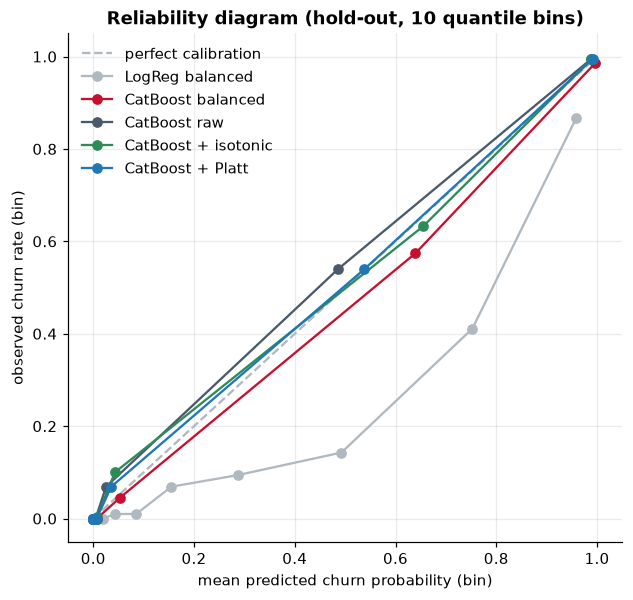

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", label="perfect calibration")
for name, p, c in [("LogReg balanced", p_lr, MUTED), ("CatBoost balanced", p_bal, RISK),
                   ("CatBoost raw", p_raw, NEUTRAL), ("CatBoost + isotonic", p_iso, GOOD),
                   ("CatBoost + Platt", p_platt, ACCENT)]:
    rel = M.reliability_table(y_test, p, n_bins=10)
    ax.plot(rel.mean_predicted, rel.observed_rate, marker="o", color=c, label=name)
ax.set_xlabel("mean predicted churn probability (bin)")
ax.set_ylabel("observed churn rate (bin)")
ax.set_title("Reliability diagram (hold-out, 10 quantile bins)")
ax.legend(loc="upper left")
save(fig, "model_calibration")
plt.show()

**Interpretation.**
* **Balanced logistic regression is badly mis-calibrated** (ECE ≈ 0.12):
  when it says 50%, only ~15% of those customers churn. Plugged into the
  profit formula, this would make the bank call far too many people. This
  is the textbook failure that calibration fixes.
* CatBoost (raw) is already close to the diagonal (ECE ≈ 0.011) — gradient
  boosting trained on log-loss is usually reasonably calibrated. Platt
  halves the ECE (≈ 0.005); isotonic gives a similar ECE but creates ties
  that slightly lower AUC/PR-AUC. **The calibration gain here is real but
  small** — honest takeaway: always *check* calibration; fix it when needed.
* With 10 quantile bins and most scores near 0, the middle of the curve
  rests on few points; ECE is the more stable summary.
* Platt/isotonic are monotone, so ranking metrics barely change.

### Which calibrator goes to production — chosen without the test set
The test table above is for *reporting*. The *decision* is made by a second
cross-validation on the training out-of-fold scores
(`src.modeling.select_calibrator`): each method is fitted on 4/5 of the OOF
scores and scored on the other 1/5. "none" (raw scores) competes too, so
calibration is only used if it actually helps.

In [9]:
use_cal, cal_cv = M.select_calibrator(oof, y_train, seed=SEED)
save_table(cal_cv.set_axis(["_".join(c) for c in cal_cv.columns], axis=1).round(5).reset_index(), "calibration_selection_cv")
print("Calibrator chosen on train OOF (lowest mean Brier):", use_cal)
display(cal_cv.round(5))

CAL_ROW = {"isotonic": "CatBoost + isotonic", "platt": "CatBoost + Platt", "none": "CatBoost (raw)"}
calibrator = {"isotonic": cal_iso, "platt": cal_platt, "none": M.IdentityCalibrator()}[use_cal]
p_final = {"isotonic": p_iso, "platt": p_platt, "none": p_raw}[use_cal]
print("Its hold-out metrics (reported, not used for the choice):")
test_table.loc[CAL_ROW[use_cal]].round(4)

cv_cb = cv_results["CatBoost depth=6"].fold_metrics.mean()
gap = pd.DataFrame({"CV mean (train folds)": cv_cb, "hold-out test": test_table.loc["CatBoost (raw)"]}).drop(index="ECE", errors="ignore")
gap["difference"] = gap["hold-out test"] - gap["CV mean (train folds)"]
gap.round(4)

Calibrator chosen on train OOF (lowest mean Brier): platt


brier               ece         
             mean      std     mean      std
method                                      
isotonic  0.01979  0.00211  0.00483  0.00226
none      0.02012  0.00203  0.00914  0.00274
platt     0.01969  0.00202  0.00591  0.00274

Its hold-out metrics (reported, not used for the choice):


,CV mean (train folds),hold-out test,difference
brier,0.0201,0.0225,0.0024
log_loss,0.0717,0.0788,0.0071
pr_auc,0.9722,0.9696,-0.0027
precision@top10%,0.9852,0.9951,0.0099
recall@top10%,0.6137,0.6215,0.0079
roc_auc,0.9938,0.9932,-0.0006


CV and hold-out agree closely (all differences < 0.01) → no sign of
overfitting to the validation scheme. Note this does **not** rule out
temporal leakage that is present in both train and test — see check 4.

### ROC, PR and gain curves (hold-out)

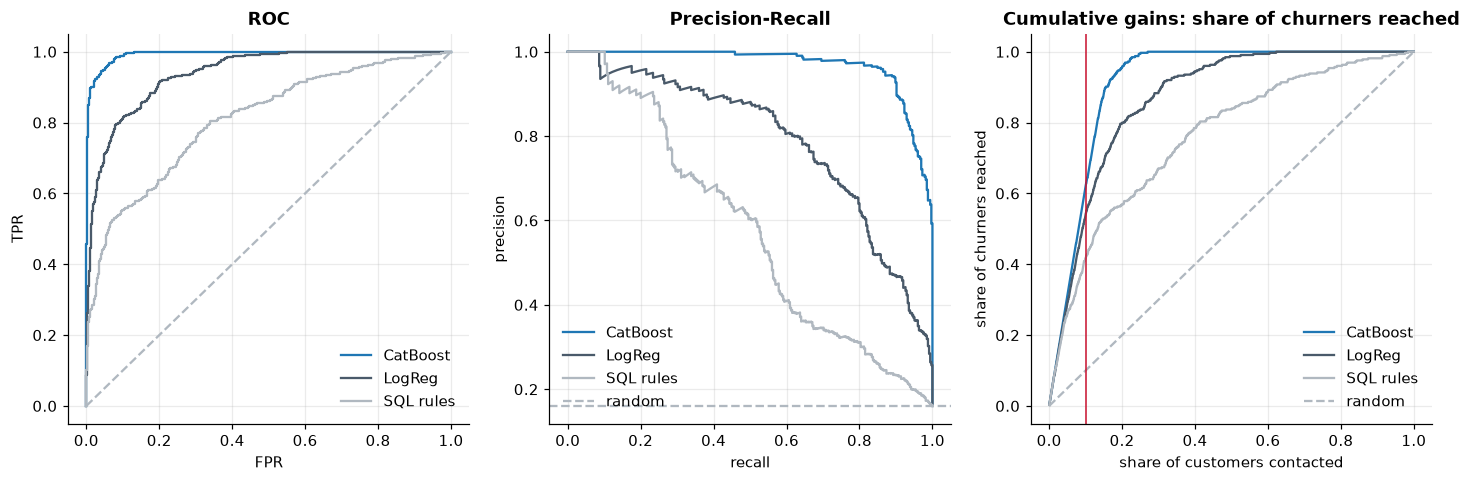

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for name, p, c in [("CatBoost", p_final, ACCENT), ("LogReg", p_lr, NEUTRAL), ("SQL rules", rules_test, MUTED)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c, label=name)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=c, label=name)
    order = np.argsort(-p, kind="stable")
    gains = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
    axes[2].plot(np.arange(1, len(p) + 1) / len(p), gains, color=c, label=name)
axes[0].plot([0, 1], [0, 1], ls="--", color=MUTED); axes[0].set(title="ROC", xlabel="FPR", ylabel="TPR")
axes[1].axhline(y_test.mean(), ls="--", color=MUTED, label="random"); axes[1].set(title="Precision-Recall", xlabel="recall", ylabel="precision")
axes[2].plot([0, 1], [0, 1], ls="--", color=MUTED, label="random")
axes[2].axvline(K, color=RISK, lw=1)
axes[2].set(title="Cumulative gains: share of churners reached", xlabel="share of customers contacted", ylabel="share of churners reached")
for ax in axes:
    ax.legend(loc="lower right" if ax is not axes[1] else "lower left")
save(fig, "model_curves")
plt.show()

## 6. Ablation: how much does the model rely on suspicious features?

In [11]:
ablations = {
    "all features": FEATURES,
    "without contacts_count_12_mon": [f for f in FEATURES if f != "contacts_count_12_mon"],
    "without all 'last-quarter change' features": [f for f in FEATURES if f not in ("total_ct_chng_q4_q1", "total_amt_chng_q4_q1")],
}
abl_rows = []
for name, feats in ablations.items():
    cats = [c for c in CATEGORICAL_COLS if c in feats]
    m = M.make_catboost(seed=SEED, depth=6, cat_features=cats).fit(X_train[feats], y_train)
    abl_rows.append({"feature set": name, **M.evaluate(y_test, m.predict_proba(X_test[feats])[:, 1], K)})
ablation = pd.DataFrame(abl_rows).set_index("feature set")
save_table(ablation.reset_index(), "ablation")
ablation.round(4)

,roc_auc,pr_auc,recall@top10%,precision@top10%,brier,log_loss
feature set,,,,,,
all features,0.9932,0.9696,0.6215,0.9951,0.0225,0.0788
without contacts_count_12_mon,0.9928,0.9677,0.6185,0.9901,0.0234,0.0809
without all 'last-quarter change' features,0.9844,0.9392,0.6123,0.9803,0.0335,0.1147


Removing `contacts_count_12_mon` barely changes performance (AUC 0.993 →
0.993), so even if it is partly post-decision information, the model does
not *depend* on it. Removing the two quarter-on-quarter change features
costs more (PR-AUC 0.97 → 0.94) but the model stays strong — its power comes
from 12-month transaction behaviour, which a bank observes before churn. **In production** the features
should be computed on a window that ends *before* the prediction date
(e.g. features from months −12…−1, label = churn in months 0…+3).

## 7. SHAP explanations
CatBoost computes exact TreeSHAP values natively (including categoricals).

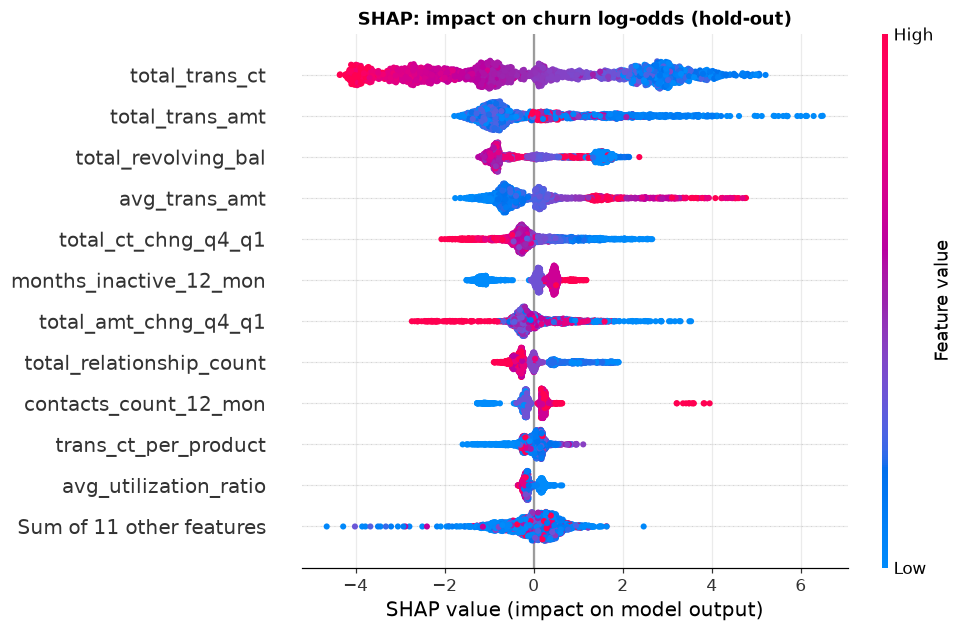

In [12]:
test_pool = Pool(X_test, cat_features=CATEGORICAL_COLS)
sv_full = final.get_feature_importance(test_pool, type="ShapValues")
shap_values, base_value = sv_full[:, :-1], sv_full[0, -1]
# Beeswarm colours points by feature value, so categoricals get integer codes;
# the original labels are kept in display_data for the waterfall plots.
X_codes = X_test.copy()
for c in CATEGORICAL_COLS:
    X_codes[c] = X_codes[c].astype("category").cat.codes
expl = shap.Explanation(values=shap_values, base_values=np.full(len(X_test), base_value),
                        data=X_codes.to_numpy(dtype=float), display_data=X_test.to_numpy(),
                        feature_names=FEATURES)

mean_abs = pd.Series(np.abs(shap_values).mean(0), index=FEATURES).sort_values(ascending=False)
save_table(mean_abs.rename("mean_abs_shap").rename_axis("feature").reset_index(), "shap_importance")

plt.figure()
shap.plots.beeswarm(expl, max_display=12, show=False)
plt.title("SHAP: impact on churn log-odds (hold-out)")
save(plt.gcf(), "shap_beeswarm")
plt.show()

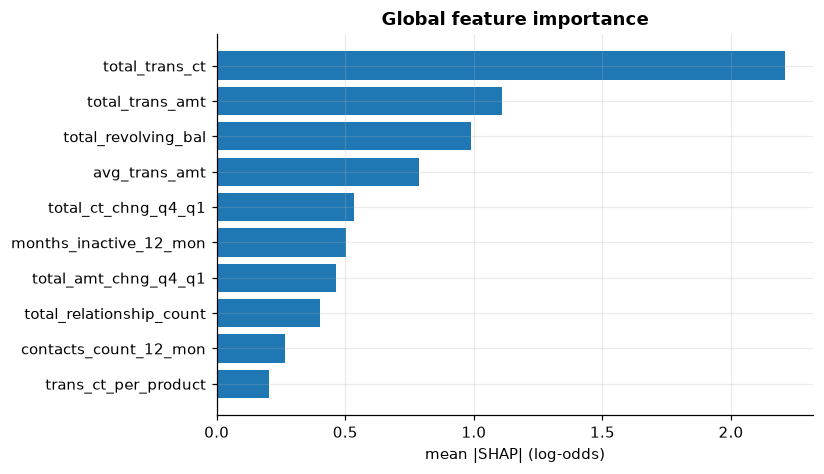

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
top = mean_abs.head(10)[::-1]
ax.barh(top.index, top.values, color=ACCENT)
ax.set_xlabel("mean |SHAP| (log-odds)")
ax.set_title("Global feature importance")
save(fig, "shap_importance")
plt.show()

**Global picture**
* **Transaction count** is by far the strongest driver: below ~60
  transactions a year risk rises sharply; above ~90 the customer is safe.
* **Transaction amount** is non-monotone (dependence plot): high risk around
  $2–3k and again around $7–10k a year, low risk at ~$4–5k. And a *high
  average ticket* (few, large purchases) raises risk.
* **Revolving balance is U-shaped:** zero balance (H3) **and** a maxed-out
  balance (the cap at $2,517, ~5% of customers, churn 31%) both raise risk;
  $1–2k is the safe zone (churn ~5%). Two different stories: "backup card"
  vs "financial stress / moved debt elsewhere".
* **Recent drop in transactions (Q4/Q1)** raises risk (H1); **inactivity**
  (H4) and **few products** (H2) matter but less.
* `contacts_count_12_mon` shows a cluster with large positive SHAP: all 54
  customers with **6 contacts churned (100%)**. That looks like contacts
  made *while closing the account* — the leakage risk flagged in section 1.
  The ablation in section 6 shows the model does not depend on this feature.
* Demographics (age, gender, income) are near the bottom (H5).

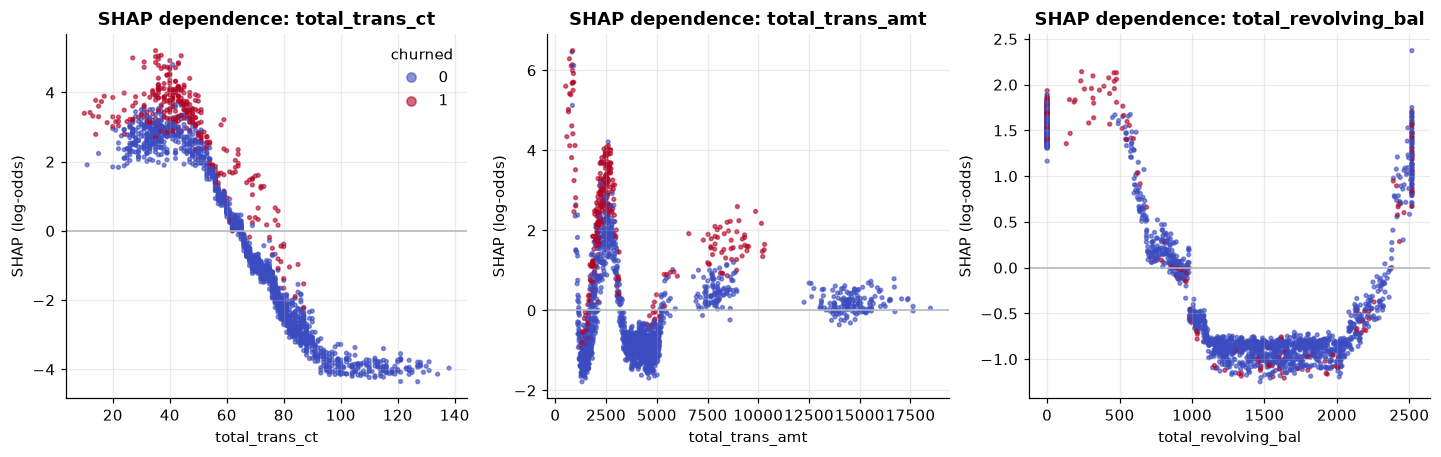

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, feat in zip(axes, ["total_trans_ct", "total_trans_amt", "total_revolving_bal"]):
    j = FEATURES.index(feat)
    sc = ax.scatter(X_test[feat], shap_values[:, j], c=y_test, cmap="coolwarm", s=6, alpha=0.6)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set(title=f"SHAP dependence: {feat}", xlabel=feat, ylabel="SHAP (log-odds)")
axes[0].legend(*sc.legend_elements(), title="churned", loc="upper right")
save(fig, "shap_dependence")
plt.show()

### Local explanation: why is *this* customer at risk?

high_risk: clientnum=718524783, calibrated P(churn)=1.00, actual churned=1


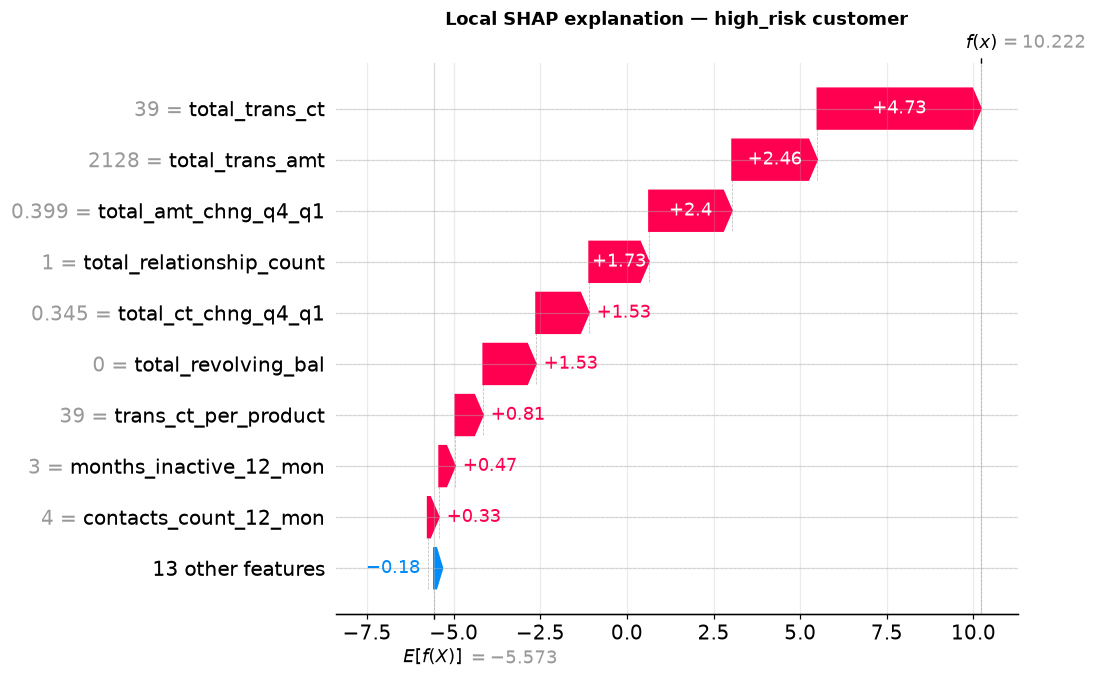

borderline: clientnum=719091333, calibrated P(churn)=0.50, actual churned=0


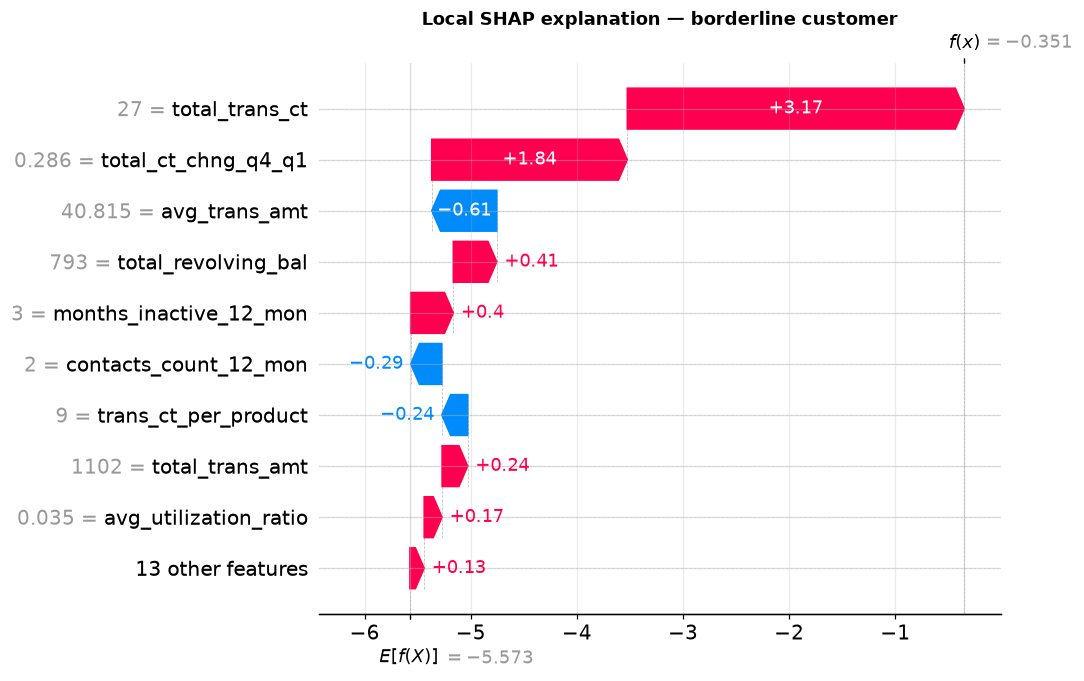

In [15]:
order = np.argsort(-p_final)
i_high = int(order[5])                      # one of the riskiest customers
i_mid = int(np.argmin(np.abs(p_final - 0.5)))  # a borderline customer
for i, label in [(i_high, "high_risk"), (i_mid, "borderline")]:
    print(f"{label}: clientnum={df.loc[X_test.index[i], 'clientnum']}, "
          f"calibrated P(churn)={p_final[i]:.2f}, actual churned={y_test.iloc[i]}")
    plt.figure()
    shap.plots.waterfall(expl[i], max_display=10, show=False)
    plt.title(f"Local SHAP explanation — {label} customer")
    save(plt.gcf(), f"shap_waterfall_{label}")
    plt.show()

SHAP values are additive in **log-odds**: base value (average log-odds) +
sum of contributions = this customer's log-odds. A call-centre script can
be built from the top-3 red bars ("you've used the card much less lately…").

## 8. Persist artefacts for the business / A/B / cross-sell notebooks

In [16]:
models_dir = path("models")
final.save_model(str(models_dir / "catboost_churn.cbm"))
joblib.dump(calibrator, models_dir / "calibrator.joblib")
joblib.dump({"features": FEATURES, "cat_features": CATEGORICAL_COLS, "calibration": use_cal,
             "seed": SEED, "test_metrics": test_table.loc[CAL_ROW[use_cal]].to_dict()},
            models_dir / "model_meta.joblib")

# OOF calibrated predictions on TRAIN are used to choose the campaign size
# without peeking at the test set.
oof_df = df.loc[X_train.index, ["clientnum"]].assign(churned=y_train.values,
                                                       proba=calibrator.predict(oof))
oof_df.to_csv(path("processed") / "train_oof_predictions.csv", index=False)

# Training features = the baseline for drift monitoring (src/monitoring.py, src/score.py)
X_train.to_csv(models_dir / "train_reference.csv", index=False)

test_df = df.loc[X_test.index].copy()
test_df["proba_raw"] = p_raw
test_df["proba"] = p_final
test_df.to_csv(path("processed") / "test_predictions.csv", index=False)
np.save(path("processed") / "test_shap_values.npy", shap_values)
print("saved:", sorted(p.name for p in models_dir.iterdir()))

saved: ['calibrator.joblib', 'catboost_churn.cbm', 'model_meta.joblib', 'train_reference.csv']
